## NinaPro DB5 EMG Calibration 

In [2]:
# Imports

import numpy as np
import pandas as pd
from scipy.io import loadmat
import matplotlib.pyplot as plt


## Step 1, Task 1: Load a file and see what's inside

In [3]:

DATA_PATH = r"data\s1\S1_E2_A1.mat"
data = loadmat(DATA_PATH)
for key, value in data.items():
    if not key.startswith("__"):
        print(key, value.shape)
#data.value.shape

emg (179901, 16)
acc (179901, 3)
stimulus (179901, 1)
glove (179901, 22)
subject (1, 1)
exercise (1, 1)
repetition (179901, 1)
restimulus (179901, 1)
rerepetition (179901, 1)
age (1, 1)
circumference (1, 1)
frequency (1, 1)
gender (1,)
height (1, 1)
weight (1, 1)
laterality (1,)
sensor (1,)


In [4]:
# Calculate the number of samples and the total time of the EMG recording

num_samples = data['emg'].shape[0]
num_channels = data['emg'].shape[1]
sampling_freq = data['frequency'].item()
total_time = num_samples / sampling_freq
print(f"{total_time} seconds")
total_time_in_minutes = total_time / 60
print(f"{total_time_in_minutes} minutes")


# data['frequency'].item()
# data['frequency'][0][0]


# data['frequency'] has shape (1, 1), an array inside an array.
# [0] only removes one layer and leaves an array of shape (1,). 
# Try printing data['frequency'][0] on its own and look at the shape.
#You must to go down both levels to reach the number. 
# To do that: index twice, use [0, 0], or use the .item() method on the array. 


899.505 seconds
14.99175 minutes


## Step 1, Task 2: Plot 5 seconds of EMG

In [5]:
# Number of samples in 5 seconds

num_samples_5s = sampling_freq * 5
print(f"Number of samples in 5 seconds: {num_samples_5s}")

first_gesture = data['restimulus'] != 0 
index_first_gesture = np.argmax(first_gesture)  # Gives the index of the first occurrence of a non-zero value in the restimulus array,
                                                # which corresponds to the first non-rest gesture.

# For slicing
start = index_first_gesture - sampling_freq  # Start index for the segment (1 second before the first gesture)
stop = start + num_samples_5s                # End index for the segment (5 seconds after the first gesture)

print(f"Start index: {start}, Stop index: {stop}")

# This is our y values to plot on the graph.
segment = data['emg'][start:stop, :]  # 5 seconds starting 1 s before the first gesture
print(segment)                        # Print the first 5 samples of the EMG data for the first gesture
                                      #across all channels.
print(segment.shape)                  # verify shape is same as time and channels i.e. (1000, 16)

Number of samples in 5 seconds: 1000
Start index: 1580, Stop index: 2580
[[ -1.  -1.  -1. ...   0.   0.  -2.]
 [ -4.  -3.   0. ...   0.  -1.   0.]
 [  1.   1.   0. ...   0.  -1.  -2.]
 ...
 [ -3.   1.   0. ...  -1.   2.  17.]
 [ -4.   1.   1. ...   0.  -5. -13.]
 [ -4.   1.  -1. ...  -3. -13. -25.]]
(1000, 16)


(1000,)


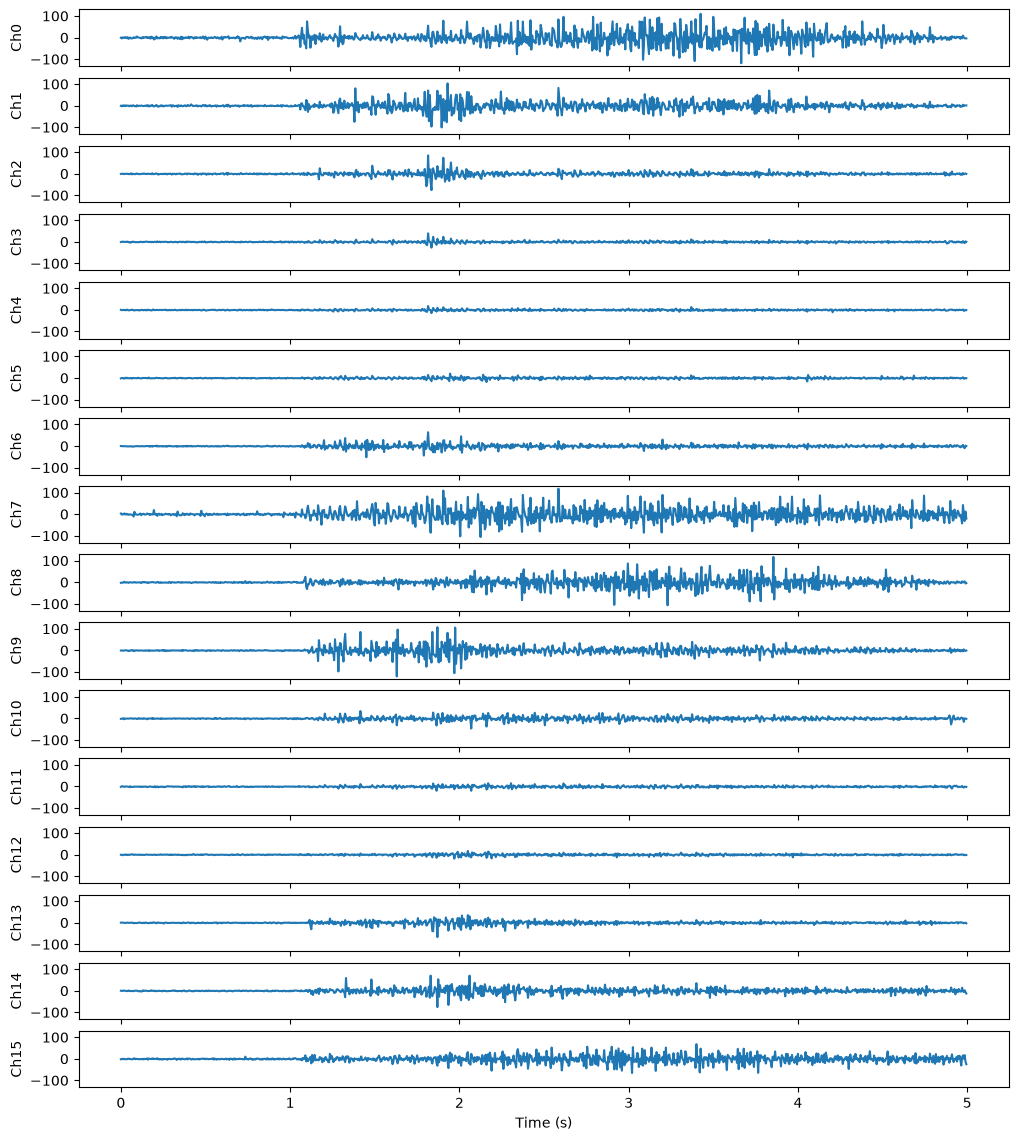

In [6]:
# Gives time values to the segment
# This is our x values to plot on the graph.

time_values = np.arange(num_samples_5s) / sampling_freq  # Create an array of time values corresponding to the samples in the segment, in seconds.
print(time_values.shape)

# Plotting the EMG data for the first gesture across all channels
fig, axes = plt.subplots(16, 1, sharex=True, sharey=True, figsize=(12, 14))

for i in range(16):
    axes[i].plot(time_values, segment[:, i])
    axes[i].set_ylabel(f'Ch{i}')
    
axes[-1].set_xlabel('Time (s)')
save_path = r"first_gesture_segment.png"
plt.savefig(save_path)
plt.show()


## Step 1, Task 3: `stimulus` vs `restimulus`

Labels disagree on 38031 of 179901 samples (21.1%)


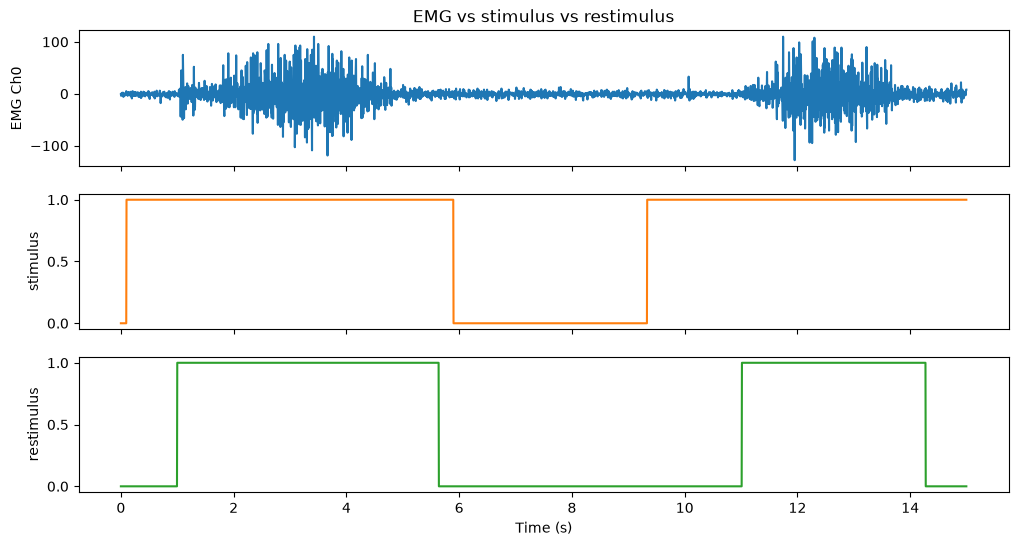

In [7]:
# Plot EMG (Ch0) against stimulus and restimulus over a 15 second window
# so we can see several repetitions start and stop.

num_samples_15s = sampling_freq * 15

# For slicing (same start/stop for all three, so they line up in time)
start_15s = index_first_gesture - sampling_freq  # 1 second before the first gesture
stop_15s = start_15s + num_samples_15s           # 15 seconds after start_15s

emg_ch0_15s = data['emg'][start_15s:stop_15s, 0]                   # Ch0 only, shape (3000,)
stimulus_15s = data['stimulus'][start_15s:stop_15s].ravel()        # (3000, 1) -> (3000,)
restimulus_15s = data['restimulus'][start_15s:stop_15s].ravel()    # (3000, 1) -> (3000,)

time_values_15s = np.arange(num_samples_15s) / sampling_freq  # x values in seconds

# How often do the two labels disagree? (whole recording, not just this window)
disagree = data['stimulus'].ravel() != data['restimulus'].ravel()
print(f"Labels disagree on {disagree.sum()} of {num_samples} samples "
      f"({disagree.mean() * 100:.1f}%)")

# Plotting
fig, axes = plt.subplots(3, 1, sharex=True, figsize=(12, 6))

axes[0].plot(time_values_15s, emg_ch0_15s)
axes[0].set_ylabel('EMG Ch0')
axes[0].set_title('EMG vs stimulus vs restimulus')

axes[1].plot(time_values_15s, stimulus_15s, color='tab:orange')
axes[1].set_ylabel('stimulus')

axes[2].plot(time_values_15s, restimulus_15s, color='tab:green')
axes[2].set_ylabel('restimulus')

axes[-1].set_xlabel('Time (s)')
save_path = r"stimulus_vs_restimulus.png"
fig.savefig(save_path, dpi=150)
plt.show()


## Step 2: Windowing and features
`With dummy data`

In [8]:
"Windowing on dummy data to test the function"

'Window Length: 250ms = 50 samples'
'Step: 125ms = 25 samples' 
# Each window starts 25 samples after the previous window, so there is an overlap of 50% between consecutive windows. 
# This means that each window shares half of its samples with the previous window, allowing for a more continuous representation of the signal over time.

window_length = 50  # samples
step_size = 25      # samples
num_samples = data['emg'].shape[0] 
#print(f"Total samples: {num_samples}")

'Calculate the total number of windows for the entire EMG sample size'
'Formula:num_windows = ((num_samples - window_length) // step_size) + 1'


toy = np.arange(20).reshape(10, 2)   # 10 samples, 2 channels
# print(toy)

def make_windows(toy, window_length = 4, step_size = 2):
    num_samples = toy.shape[0]
    windows = []
    num_windows = ((num_samples - window_length) // step_size) + 1 
    for i in range(num_windows):
        start = i * step_size
        end = start + window_length
        
        # print(i, start, end)
        
        window = toy[start:end, :]
        windows.append(window)
        
    stacked = np.stack(windows)  
    
    # print(windows)   # the list of all windows
    # print(np.stack(windows))  # the list of all windows stacked into a single array
    return stacked            # np.stack lines the four (4, 2) arrays up along a new first axis, 
                              # giving (4 windows, 4 samples, 2 channels).
                              # (axis 0 = 4 windows, axis 1 = 4 samples, axis 2 = 2 channels)
                              
result = make_windows(toy, window_length=4, step_size=2)
# print(len(result))        # how many windows
# print(result[0])          # first window
# print(result[1])          # second window
result.shape


(4, 4, 2)

In [9]:
np.mean(np.abs(result), axis=1)

array([[ 3.,  4.],
       [ 7.,  8.],
       [11., 12.],
       [15., 16.]])

## Step 2: Windowing and features

**Task 1** : `With real EMG data` 


In [10]:
"Windowing on the real EMG data"

'Window Length: 250ms = 50 samples'
'Step: 125ms = 25 samples'

window_length = 50  # samples
step_size = 25      # samples

emg = data['emg']                 # (num_samples, num_channels) = (179901, 16)
num_samples = emg.shape[0]
num_channels = emg.shape[1]

'Formula: num_windows = ((num_samples - window_length) // step_size) + 1'
expected_num_windows = ((num_samples - window_length) // step_size) + 1
print(f"Expected number of windows: {expected_num_windows}")


def make_windows(x, window_length, step_size):
    num_samples = x.shape[0]
    num_windows = ((num_samples - window_length) // step_size) + 1
    windows = []
    for i in range(num_windows):
        start = i * step_size
        end = start + window_length
        window = x[start:end, :]
        windows.append(window)

    # stack once, AFTER the loop (stacking inside the loop would redo the work for every window)
    return np.stack(windows)   # (num_windows, window_length, num_channels)


emg_windows = make_windows(emg, window_length, step_size)
print(emg_windows.shape)       # expected: (7195, 50, 16)
print(emg_windows.shape == (expected_num_windows, window_length, num_channels))


Expected number of windows: 7195
(7195, 50, 16)
True


In [11]:
mav = np.mean(np.abs(emg_windows), axis=1)
mav.shape

(7195, 16)

In [12]:
# emg_windows: (num_windows, window_length, num_channels) = (7195, 50, 16)
# axis=1 is the sample axis inside each window, so it is the one we collapse.
# (mav was computed in the cell above)

# RMS: Root Mean Square -> like MAV, but large swings count for more
rms = np.sqrt(np.mean(emg_windows ** 2, axis=1))           # (7195, 16)

# WL: Waveform Length -> total distance the signal travels inside the window
# np.diff gives (7195, 49, 16): one difference between each pair of neighbouring samples
wl = np.sum(np.abs(np.diff(emg_windows, axis=1)), axis=1)  # (7195, 16)

print(mav.shape, rms.shape, wl.shape)

# One feature vector per window: [16 MAV | 16 RMS | 16 WL] = 48 numbers
features = np.concatenate([mav, rms, wl], axis=1)          # (7195, 48)
print(features.shape)
print(np.isnan(features).sum())                            # sanity check: should be 0


(7195, 16) (7195, 16) (7195, 16)
(7195, 48)
0


In [13]:
"One label per window: the majority gesture in that window"

# Window the labels with the SAME function, window length and step as the EMG,
# so window i of the labels is the same stretch of time as row i of the features.
restimulus_windows = make_windows(data['restimulus'], window_length, step_size)    # (7195, 50, 1)
restimulus_windows = restimulus_windows[:, :, 0].astype(int)                       # (7195, 50)

y = []        # majority gesture of each window (0 = rest, 1..17 = gestures)
purity = []   # how much of the window that gesture covers (1.0 = the whole window)

for window in restimulus_windows:
    counts = np.bincount(window)      # counts[g] = how many of the 50 samples are gesture g
    majority = counts.argmax()        # the gesture with the highest count
    y.append(majority)
    purity.append(counts.max() / window_length)

y = np.array(y)             # (7195,)
purity = np.array(purity)   # (7195,)

print(y.shape)
print("windows per gesture:", np.bincount(y))
print(f"mixed windows (purity < 1): {(purity < 1).sum()} ({(purity < 1).mean() * 100:.1f}%)")

# Same idea for the repetition number (needed for splitting in Step 3)
rerepetition_windows = make_windows(data['rerepetition'], window_length, step_size)
rerepetition_windows = rerepetition_windows[:, :, 0].astype(int)                   # (7195, 50)

rep = []      # majority repetition number of each window
for window in rerepetition_windows:
    rep.append(np.bincount(window).argmax())

rep = np.array(rep)         # (7195,)
print("repetitions:", np.unique(rep))

print(rerepetition_windows.shape)


(7195,)
windows per gesture: [4146  214  158  175  186  171  160  199  166  183  190  206  184  188
  149  136  206  178]
mixed windows (purity < 1): 397 (5.5%)
repetitions: [0 1 2 3 4 5 6]
(7195, 50)


## Step 3: Honest evaluation, leave one repetition out
`Train on 5 repetitions, test on the 6th, repeat for each repetition`

In [14]:
"Leave one repetition out with LDA"

from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

# The 5 windows with rep = 0 come from the short rest at the very end of the recording.
# They do not belong to any of the 6 repetitions, so we leave them out.
keep = rep != 0
features_kept = features[keep]
y_kept = y[keep]
rep_kept = rep[keep]
print(features_kept.shape, y_kept.shape, rep_kept.shape)

accuracies = []

for r in range(1, 7):
    # Test = every window from repetition r, Train = all the other repetitions
    test_mask = rep_kept == r
    train_mask = rep_kept != r

    X_train = features_kept[train_mask]
    y_train = y_kept[train_mask]
    X_test = features_kept[test_mask]
    y_test = y_kept[test_mask]

    model = LinearDiscriminantAnalysis(solver="lsqr", shrinkage="auto")
    model.fit(X_train, y_train)

    accuracy = model.score(X_test, y_test)   # fraction of test windows predicted correctly
    accuracies.append(accuracy)
    print(f"Test repetition {r}: {accuracy * 100:.1f}%")

print(f"Mean accuracy: {np.mean(accuracies) * 100:.1f}%")

# Reference: how often would we be right if we always guessed rest?
rest_share = np.mean(y_kept == 0)
print(f"Always guessing rest: {rest_share * 100:.1f}%")


(7190, 48) (7190,) (7190,)
Test repetition 1: 79.6%
Test repetition 2: 79.7%
Test repetition 3: 82.2%
Test repetition 4: 80.3%
Test repetition 5: 81.1%
Test repetition 6: 78.7%
Mean accuracy: 80.3%
Always guessing rest: 57.6%


## Step 3b: All ten subjects
`Same pipeline for every subject (exercise 2), then test each person two ways`

In [15]:
"A function that builds features, labels and repetition numbers for any subject"

# This is the same steps as before (windows -> MAV/RMS/WL -> majority label), just wrapped in a function.
# It uses make_windows, window_length and step_size from the cells above.

def load_subject(subject_number):
    path = f"data/s{subject_number}/S{subject_number}_E2_A1.mat"
    mat = loadmat(path)

    # EMG -> windows -> features
    emg_windows = make_windows(mat['emg'], window_length, step_size)
    mav = np.mean(np.abs(emg_windows), axis=1)
    rms = np.sqrt(np.mean(emg_windows ** 2, axis=1))
    wl = np.sum(np.abs(np.diff(emg_windows, axis=1)), axis=1)
    features = np.concatenate([mav, rms, wl], axis=1)

    # Gesture label of each window (majority vote)
    restimulus_windows = make_windows(mat['restimulus'], window_length, step_size)
    restimulus_windows = restimulus_windows[:, :, 0].astype(int)
    y = []
    for window in restimulus_windows:
        y.append(np.bincount(window).argmax())
    y = np.array(y)

    # Repetition number of each window (majority vote)
    rerepetition_windows = make_windows(mat['rerepetition'], window_length, step_size)
    rerepetition_windows = rerepetition_windows[:, :, 0].astype(int)
    rep = []
    for window in rerepetition_windows:
        rep.append(np.bincount(window).argmax())
    rep = np.array(rep)

    return features, y, rep


In [16]:
"Load all ten subjects and check that they look alike"

subjects = {}     # subject number -> (features, y, rep)

for subject_number in range(1, 11):
    features_s, y_s, rep_s = load_subject(subject_number)
    subjects[subject_number] = (features_s, y_s, rep_s)

    rest_share = np.mean(y_s == 0)
    print(f"Subject {subject_number}: features {features_s.shape}, "
          f"gestures {len(np.unique(y_s)) - 1}, repetitions {np.unique(rep_s)}, "
          f"rest share {rest_share * 100:.1f}%")


Subject 1: features (7195, 48), gestures 17, repetitions [0 1 2 3 4 5 6], rest share 57.6%
Subject 2: features (8156, 48), gestures 17, repetitions [0 1 2 3 4 5 6], rest share 66.5%
Subject 3: features (7376, 48), gestures 17, repetitions [0 1 2 3 4 5 6], rest share 62.6%
Subject 4: features (8247, 48), gestures 17, repetitions [0 1 2 3 4 5 6], rest share 63.0%
Subject 5: features (8244, 48), gestures 17, repetitions [0 1 2 3 4 5 6], rest share 63.0%
Subject 6: features (8216, 48), gestures 17, repetitions [1 2 3 4 5 6], rest share 59.3%
Subject 7: features (8359, 48), gestures 17, repetitions [0 1 2 3 4 5 6], rest share 62.6%
Subject 8: features (8249, 48), gestures 17, repetitions [0 1 2 3 4 5 6], rest share 66.0%
Subject 9: features (8328, 48), gestures 17, repetitions [0 1 2 3 4 5 6], rest share 65.9%
Subject 10: features (8561, 48), gestures 17, repetitions [0 1 2 3 4 5 6], rest share 64.6%


In [17]:
"Within-subject: for each person, train and test on THEIR OWN data (leave one repetition out)"

within_subject = {}     # subject number -> mean accuracy

for subject_number in range(1, 11):
    features_s, y_s, rep_s = subjects[subject_number]

    # Leave out the few windows with rep = 0 (end of the recording)
    keep = rep_s != 0
    features_s = features_s[keep]
    y_s = y_s[keep]
    rep_s = rep_s[keep]

    accuracies = []
    for r in range(1, 7):
        test_mask = rep_s == r
        train_mask = rep_s != r

        model = LinearDiscriminantAnalysis(solver="lsqr", shrinkage="auto")
        model.fit(features_s[train_mask], y_s[train_mask])
        accuracies.append(model.score(features_s[test_mask], y_s[test_mask]))

    within_subject[subject_number] = np.mean(accuracies)
    rest_share = np.mean(y_s == 0)
    print(f"Subject {subject_number}: {within_subject[subject_number] * 100:.1f}%   "
          f"(always guessing rest: {rest_share * 100:.1f}%)")

print(f"Average over subjects: {np.mean(list(within_subject.values())) * 100:.1f}%")


Subject 1: 80.3%   (always guessing rest: 57.6%)
Subject 2: 84.6%   (always guessing rest: 66.4%)
Subject 3: 83.7%   (always guessing rest: 62.5%)
Subject 4: 81.3%   (always guessing rest: 63.0%)
Subject 5: 81.3%   (always guessing rest: 63.0%)
Subject 6: 78.0%   (always guessing rest: 59.3%)
Subject 7: 79.8%   (always guessing rest: 62.5%)
Subject 8: 83.3%   (always guessing rest: 65.9%)
Subject 9: 84.7%   (always guessing rest: 65.8%)
Subject 10: 82.6%   (always guessing rest: 64.5%)
Average over subjects: 81.9%


In [18]:
"Cross-subject: train on 9 people, test on the 10th (a person the model has never seen)"

cross_subject = {}     # test subject number -> accuracy

for test_subject in range(1, 11):
    # Collect the training data from the 9 other people
    train_features = []
    train_y = []
    for other_subject in range(1, 11):
        if other_subject != test_subject:
            train_features.append(subjects[other_subject][0])
            train_y.append(subjects[other_subject][1])
    train_features = np.concatenate(train_features, axis=0)
    train_y = np.concatenate(train_y, axis=0)

    # The test person: ALL of their windows
    test_features = subjects[test_subject][0]
    test_y = subjects[test_subject][1]

    model = LinearDiscriminantAnalysis(solver="lsqr", shrinkage="auto")
    model.fit(train_features, train_y)
    cross_subject[test_subject] = model.score(test_features, test_y)

print("Subject   within-subject   cross-subject")
for subject_number in range(1, 11):
    print(f"{subject_number:7d}   {within_subject[subject_number] * 100:13.1f}%   "
          f"{cross_subject[subject_number] * 100:12.1f}%")

print(f"Average   {np.mean(list(within_subject.values())) * 100:13.1f}%   "
      f"{np.mean(list(cross_subject.values())) * 100:12.1f}%")


Subject   within-subject   cross-subject
      1            80.3%           65.7%
      2            84.6%           73.8%
      3            83.7%           60.7%
      4            81.3%           68.1%
      5            81.3%           67.4%
      6            78.0%           60.4%
      7            79.8%           71.3%
      8            83.3%           71.1%
      9            84.7%           75.3%
     10            82.6%           66.7%
Average            81.9%           68.0%


## M0 Step A: One loader that works for any subject
`Returns windows, gesture labels and repetition numbers, and checks the file before trusting it`

In [19]:
"The loader: windows, gesture label and repetition number for any subject"

# Uses make_windows from the Step 2 cell above.

def majority_label(label_windows):
    # label_windows: (num_windows, window_length) -> one label per window, the most common one
    labels = []
    for window in label_windows:
        labels.append(np.bincount(window).argmax())
    return np.array(labels)


def load_db5(subject_number, exercise_number=2, window_length=50, step_size=25):
    path = f"data/s{subject_number}/S{subject_number}_E{exercise_number}_A1.mat"
    mat = loadmat(path)

    # Check 1: the variables we need must be in the file (trust the file, not memory)
    for name in ['emg', 'restimulus', 'rerepetition', 'frequency']:
        if name not in mat:
            raise KeyError(f"'{name}' is missing from {path}")

    emg = mat['emg']
    restimulus = mat['restimulus']
    rerepetition = mat['rerepetition']
    sampling_freq = mat['frequency'].item()

    # Check 2: EMG and labels must have the same number of rows, otherwise window i would not line up
    if not (emg.shape[0] == restimulus.shape[0] == rerepetition.shape[0]):
        raise ValueError(f"EMG and labels have different lengths in {path}")

    # Windows: the SAME function and settings for the EMG and for both label arrays
    emg_windows = make_windows(emg, window_length, step_size)                                      # (num_windows, 50, 16)
    restimulus_windows = make_windows(restimulus, window_length, step_size)[:, :, 0].astype(int)   # (num_windows, 50)
    rerepetition_windows = make_windows(rerepetition, window_length, step_size)[:, :, 0].astype(int)

    # One gesture label and one repetition number per window
    y = majority_label(restimulus_windows)      # (num_windows,)
    rep = majority_label(rerepetition_windows)  # (num_windows,)

    return emg_windows, y, rep, sampling_freq


In [20]:
"Check the loader on every subject (windows are not kept, only a summary is printed)"

expected_sampling_freq = 200

for subject_number in range(1, 11):
    emg_windows_s, y_s, rep_s, sampling_freq_s = load_db5(subject_number)

    # Do the three outputs line up, is the sampling rate what we assumed, is there any NaN?
    same_length = emg_windows_s.shape[0] == len(y_s) == len(rep_s)
    right_freq = sampling_freq_s == expected_sampling_freq
    has_nan = np.isnan(emg_windows_s).any()

    num_gestures = len(np.unique(y_s)) - 1     # minus 1 because 0 = rest
    rest_share = np.mean(y_s == 0)

    # Every gesture should appear in every repetition (1..6), otherwise a repetition split breaks
    missing = 0
    for g in range(1, 18):
        for r in range(1, 7):
            if np.sum((y_s == g) & (rep_s == r)) == 0:
                missing += 1

    print(f"Subject {subject_number}: windows {emg_windows_s.shape}, same length: {same_length}, "
          f"200 Hz: {right_freq}, NaN: {has_nan}, gestures: {num_gestures}, "
          f"rest {rest_share * 100:.1f}%, gesture/repetition pairs with no windows: {missing}")


Subject 1: windows (7195, 50, 16), same length: True, 200 Hz: True, NaN: False, gestures: 17, rest 57.6%, gesture/repetition pairs with no windows: 0
Subject 2: windows (8156, 50, 16), same length: True, 200 Hz: True, NaN: False, gestures: 17, rest 66.5%, gesture/repetition pairs with no windows: 0
Subject 3: windows (7376, 50, 16), same length: True, 200 Hz: True, NaN: False, gestures: 17, rest 62.6%, gesture/repetition pairs with no windows: 0
Subject 4: windows (8247, 50, 16), same length: True, 200 Hz: True, NaN: False, gestures: 17, rest 63.0%, gesture/repetition pairs with no windows: 0
Subject 5: windows (8244, 50, 16), same length: True, 200 Hz: True, NaN: False, gestures: 17, rest 63.0%, gesture/repetition pairs with no windows: 0
Subject 6: windows (8216, 50, 16), same length: True, 200 Hz: True, NaN: False, gestures: 17, rest 59.3%, gesture/repetition pairs with no windows: 0
Subject 7: windows (8359, 50, 16), same length: True, 200 Hz: True, NaN: False, gestures: 17, rest 6

## M0 Step B: Confusion matrix and per-class recall
`Which gestures does LDA recognise well, and which ones does it mix up? (one subject, leave one repetition out)`

In [21]:
"Two functions: features from windows, and held-out predictions for every window"

from sklearn.metrics import confusion_matrix

def extract_features(emg_windows):
    # emg_windows: (num_windows, window_length, num_channels)
    # axis=1 is the sample axis inside each window, so it is the one we collapse
    mav = np.mean(np.abs(emg_windows), axis=1)                    # (num_windows, 16)
    rms = np.sqrt(np.mean(emg_windows ** 2, axis=1))              # (num_windows, 16)
    wl = np.sum(np.abs(np.diff(emg_windows, axis=1)), axis=1)     # (num_windows, 16)
    return np.concatenate([mav, rms, wl], axis=1)                 # (num_windows, 48)


def held_out_predictions(features, y, rep, equal_priors=False):
    # For every window, the prediction of a model that never saw that window's repetition.
    # equal_priors=False: LDA assumes rest is as common as it is in the data (most windows are rest)
    # equal_priors=True:  LDA treats every class as equally likely, so rest is less favoured

    # Leave out the few windows with rep = 0 (rest at the very end of the recording)
    keep = rep != 0
    features = features[keep]
    y = y[keep]
    rep = rep[keep]

    y_pred = np.zeros(len(y), dtype=int)

    for r in range(1, 7):
        test_mask = rep == r        # test: every window of repetition r
        train_mask = rep != r       # train: all the other repetitions

        if equal_priors:
            num_classes = len(np.unique(y[train_mask]))
            priors = np.ones(num_classes) / num_classes
        else:
            priors = None           # None = use the class shares in the training data

        model = LinearDiscriminantAnalysis(solver="lsqr", shrinkage="auto", priors=priors)
        model.fit(features[train_mask], y[train_mask])
        y_pred[test_mask] = model.predict(features[test_mask])

    return y, y_pred


In [22]:
"Subject 1: held-out predictions, confusion matrix and recall of every class"

subject_number = 1

emg_windows_s, y_s, rep_s, sampling_freq_s = load_db5(subject_number)
features_s = extract_features(emg_windows_s)
y_true, y_pred = held_out_predictions(features_s, y_s, rep_s)

# Confusion matrix: row = the TRUE class, column = what the model PREDICTED
# cm[g, h] = how many windows of true class g were predicted as class h
cm = confusion_matrix(y_true, y_pred)
print(cm.shape)    # (18, 18): rest + 17 gestures

# Recall of a class = of all windows that REALLY belong to it, how many did we get right?
# The correct ones sit on the diagonal cm[g, g], and the row sum is all windows of class g.
recalls = []
print("class  windows  recall")
for g in range(cm.shape[0]):
    recall = cm[g, g] / cm[g].sum()
    recalls.append(recall)
    print(f"{g:5d}  {cm[g].sum():7d}  {recall * 100:5.1f}%")

print(f"Overall accuracy: {np.mean(y_true == y_pred) * 100:.1f}%")
print(f"Average recall over the 18 classes: {np.mean(recalls) * 100:.1f}%")


(18, 18)
class  windows  recall
    0     4141   99.3%
    1      214   79.4%
    2      158   82.3%
    3      175   78.3%
    4      186   42.5%
    5      171   56.1%
    6      160   68.1%
    7      199   66.3%
    8      166   54.8%
    9      183   44.3%
   10      190   35.8%
   11      206   41.7%
   12      184   42.9%
   13      188   38.8%
   14      149   47.7%
   15      136   72.8%
   16      206   43.2%
   17      178   37.1%
Overall accuracy: 80.3%
Average recall over the 18 classes: 57.3%


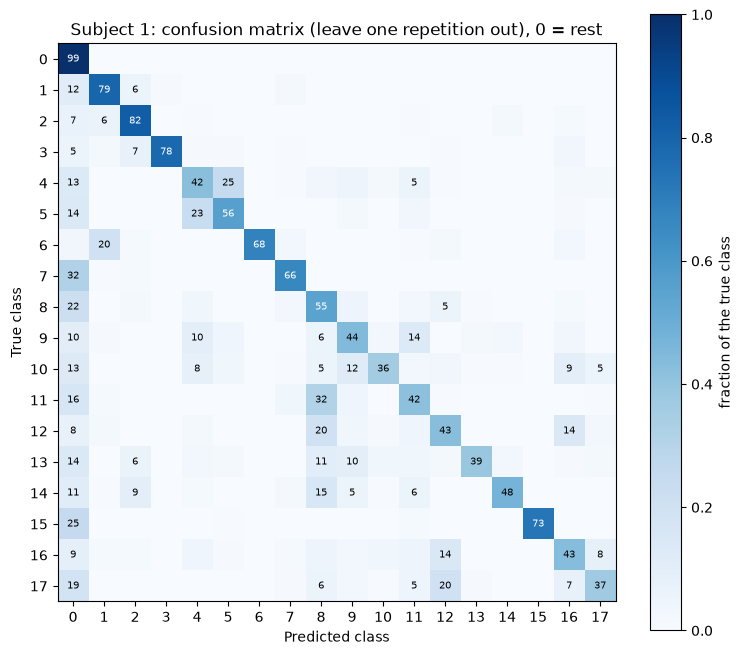

In [23]:
"Plot the confusion matrix (each row divided by its total, so a cell = fraction of that true class)"

# Divide every row by its sum: the diagonal then shows the recall of each class
cm_fraction = cm / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(9, 8))
image = ax.imshow(cm_fraction, cmap='Blues', vmin=0, vmax=1)
fig.colorbar(image, ax=ax, label='fraction of the true class')

ax.set_xticks(range(cm.shape[0]))
ax.set_yticks(range(cm.shape[0]))
ax.set_xlabel('Predicted class')
ax.set_ylabel('True class')
ax.set_title(f'Subject {subject_number}: confusion matrix (leave one repetition out), 0 = rest')

# Write the number inside each cell, only where it is at least 0.05, so the picture stays readable
for g in range(cm.shape[0]):
    for h in range(cm.shape[1]):
        if cm_fraction[g, h] >= 0.05:
            colour = 'white' if cm_fraction[g, h] > 0.5 else 'black'
            ax.text(h, g, f"{cm_fraction[g, h] * 100:.0f}", ha='center', va='center', fontsize=7, color=colour)

save_path = r"confusion_matrix_all_classes.png"
fig.savefig(save_path, dpi=150)
plt.show()


## M0 Step C: Compare two gesture sets
`Set A = 6 fist, 5 abduction of all fingers, 15 radial deviation, 16 ulnar deviation. Set B = 2, 1, 3, 15 (the best recall in the 18-class model). Both plus rest.`

In [24]:
"Evaluate a gesture set: keep only rest + the chosen gestures, retrain, test on held-out repetitions"

def evaluate_set(features, y, rep, gestures, equal_priors=False):
    classes = [0] + gestures                  # rest + the chosen gestures
    keep = np.isin(y, classes)                # True for windows that belong to one of these classes
    y_true, y_pred = held_out_predictions(features[keep], y[keep], rep[keep], equal_priors)

    recalls = []       # of all windows that REALLY are class c, how many were predicted as c?
    precisions = []    # of all windows PREDICTED as class c, how many really are c?
    for c in classes:
        recalls.append(np.mean(y_pred[y_true == c] == c))
        precisions.append(np.mean(y_true[y_pred == c] == c))
    return recalls, precisions


sets = {"A": [6, 5, 15, 16], "B": [2, 1, 3, 15]}

# Subject 1
emg_windows_s, y_s, rep_s, sampling_freq_s = load_db5(1)
features_s = extract_features(emg_windows_s)

for name, gestures in sets.items():
    for equal_priors in [False, True]:
        recalls, precisions = evaluate_set(features_s, y_s, rep_s, gestures, equal_priors)
        classes = [0] + gestures
        print(f"Set {name}, equal priors = {equal_priors}")
        for i in range(len(classes)):
            print(f"   class {classes[i]:2d}: recall {recalls[i] * 100:5.1f}%   precision {precisions[i] * 100:5.1f}%")
        print(f"   average recall {np.mean(recalls) * 100:.1f}%")


Set A, equal priors = False
   class  0: recall  99.7%   precision  97.8%
   class  6: recall  84.4%   precision 100.0%
   class  5: recall  84.2%   precision  88.9%
   class 15: recall  77.9%   precision  98.1%
   class 16: recall  83.0%   precision  91.4%
   average recall 85.8%
Set A, equal priors = True
   class  0: recall  99.4%   precision  98.5%
   class  6: recall  91.2%   precision  96.1%
   class  5: recall  87.1%   precision  84.2%
   class 15: recall  85.3%   precision  96.7%
   class 16: recall  83.0%   precision  90.5%
   average recall 89.2%
Set B, equal priors = False
   class  0: recall  99.5%   precision  98.0%
   class  2: recall  89.9%   precision  81.6%
   class  1: recall  84.6%   precision  96.3%
   class  3: recall  81.7%   precision  96.6%
   class 15: recall  77.9%   precision  97.2%
   average recall 86.7%
Set B, equal priors = True
   class  0: recall  99.2%   precision  98.5%
   class  2: recall  90.5%   precision  80.3%
   class  1: recall  86.9%   precisi

In [25]:
"Same comparison on all ten subjects: does the better set depend on the person?"

# For each subject: average recall of the 4 gestures only (rest left out, because rest is easy)
results = {}     # (set name, equal_priors) -> list with one number per subject
for name in sets:
    for equal_priors in [False, True]:
        results[(name, equal_priors)] = []

for subject_number in range(1, 11):
    emg_windows_s, y_s, rep_s, sampling_freq_s = load_db5(subject_number)
    features_s = extract_features(emg_windows_s)

    for name, gestures in sets.items():
        for equal_priors in [False, True]:
            recalls, precisions = evaluate_set(features_s, y_s, rep_s, gestures, equal_priors)
            results[(name, equal_priors)].append(np.mean(recalls[1:]))    # [1:] skips rest

print("Average recall of the 4 gestures (rest left out)")
print("Subject   priors from data      equal priors")
print("             A       B             A       B")
for i in range(10):
    print(f"{i + 1:7d}   {results[('A', False)][i] * 100:5.1f}%  {results[('B', False)][i] * 100:5.1f}%       "
          f"{results[('A', True)][i] * 100:5.1f}%  {results[('B', True)][i] * 100:5.1f}%")

print(f"Average   {np.mean(results[('A', False)]) * 100:5.1f}%  {np.mean(results[('B', False)]) * 100:5.1f}%       "
      f"{np.mean(results[('A', True)]) * 100:5.1f}%  {np.mean(results[('B', True)]) * 100:5.1f}%")


Average recall of the 4 gestures (rest left out)
Subject   priors from data      equal priors
             A       B             A       B
      1    82.4%   83.5%        86.7%   86.9%
      2    69.0%   74.0%        70.6%   84.6%
      3    73.2%   74.5%        80.9%   81.6%
      4    68.4%   66.8%        71.3%   73.4%
      5    70.1%   66.5%        74.7%   75.8%
      6    70.9%   67.7%        77.9%   80.0%
      7    71.4%   60.0%        76.8%   65.8%
      8    69.3%   71.3%        78.9%   78.2%
      9    76.3%   72.5%        79.5%   75.3%
     10    73.2%   71.8%        76.6%   79.4%
Average    72.4%   70.9%        77.4%   78.1%


## M0 Step D: Confusion matrix for the chosen set
`Set A (6 fist, 5 abduction of all fingers, 15 radial deviation, 16 ulnar deviation) + rest. Subject 1, equal priors, leave one repetition out`

Counts (row = true class, column = predicted class):
[[4115    3   12    4    7]
 [   5  146    1    0    8]
 [  19    0  149    0    3]
 [  20    0    0  116    0]
 [  17    3   15    0  171]]


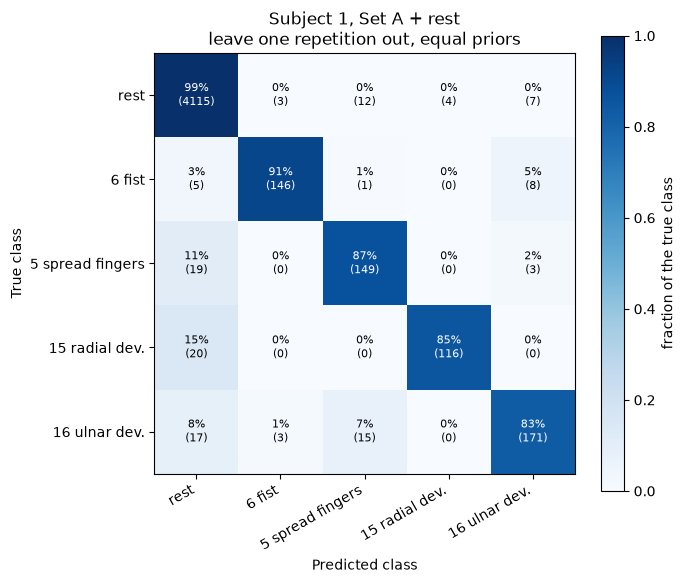

In [26]:
"Confusion matrix of the chosen set (rest + 4 gestures), Subject 1, equal priors"

chosen_gestures = [6, 5, 15, 16]
classes = [0] + chosen_gestures
class_names = ["rest", "6 fist", "5 spread fingers", "15 radial dev.", "16 ulnar dev."]

emg_windows_s, y_s, rep_s, sampling_freq_s = load_db5(1)
features_s = extract_features(emg_windows_s)

# Keep only rest + the 4 chosen gestures, then get the held-out predictions
keep = np.isin(y_s, classes)
y_true, y_pred = held_out_predictions(features_s[keep], y_s[keep], rep_s[keep], equal_priors=True)

# labels=classes puts the rows and columns in the order we listed them
cm_set = confusion_matrix(y_true, y_pred, labels=classes)
cm_set_fraction = cm_set / cm_set.sum(axis=1, keepdims=True)

print("Counts (row = true class, column = predicted class):")
print(cm_set)

fig, ax = plt.subplots(figsize=(7, 6))
image = ax.imshow(cm_set_fraction, cmap='Blues', vmin=0, vmax=1)
fig.colorbar(image, ax=ax, label='fraction of the true class')

ax.set_xticks(range(len(classes)))
ax.set_yticks(range(len(classes)))
ax.set_xticklabels(class_names, rotation=30, ha='right')
ax.set_yticklabels(class_names)
ax.set_xlabel('Predicted class')
ax.set_ylabel('True class')
ax.set_title('Subject 1, Set A + rest\nleave one repetition out, equal priors')

# Write the percentage and the count inside every cell
for g in range(len(classes)):
    for h in range(len(classes)):
        colour = 'white' if cm_set_fraction[g, h] > 0.5 else 'black'
        ax.text(h, g, f"{cm_set_fraction[g, h] * 100:.0f}%\n({cm_set[g, h]})",
                ha='center', va='center', fontsize=8, color=colour)

fig.tight_layout()
save_path = r"confusion_matrix_set_a.png"
fig.savefig(save_path, dpi=150)
plt.show()
